## Lab 5
## Name: Shaivi Bhasin
## Batch: C-C3
## Roll no: 36

In [ ]:
from sklearn.metrics._plot.roc_curve import roc_curve
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import  (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ( accuracy_score,classification_report,confusion_matrix,roc_curve,f1_score,recall_score,precision_score,roc_auc_score)
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [ ]:
df=pd.read_csv("/content/diabetes (6).csv")
print(df)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   50        1  
1                  

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.shape

(768, 9)

In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [ ]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


### Univarient Analysis

<function matplotlib.pyplot.show(close=None, block=None)>

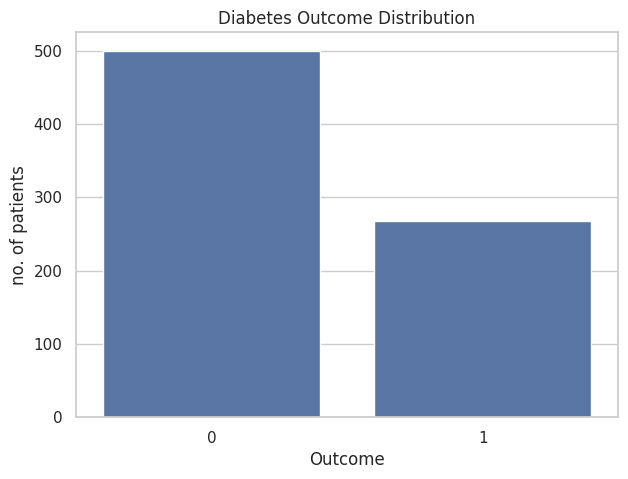

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(x="Outcome",data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("no. of patients")
plt.show

### Bivarient analysis

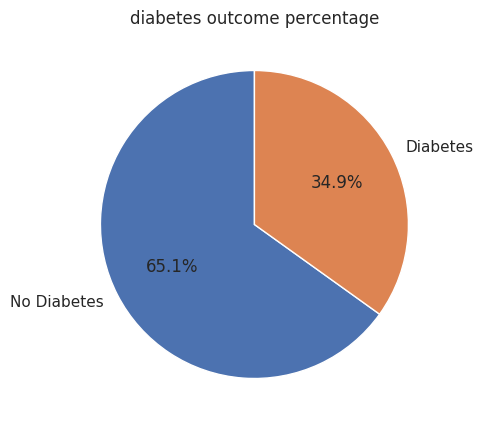

In [ ]:
target_percentage = df["Outcome"].value_counts()
plt.figure(figsize=(7,5))
plt.pie(target_percentage,labels=["No Diabetes","Diabetes"],autopct="%1.1f%%",startangle=90)
plt.title("diabetes outcome percentage")
plt.show()

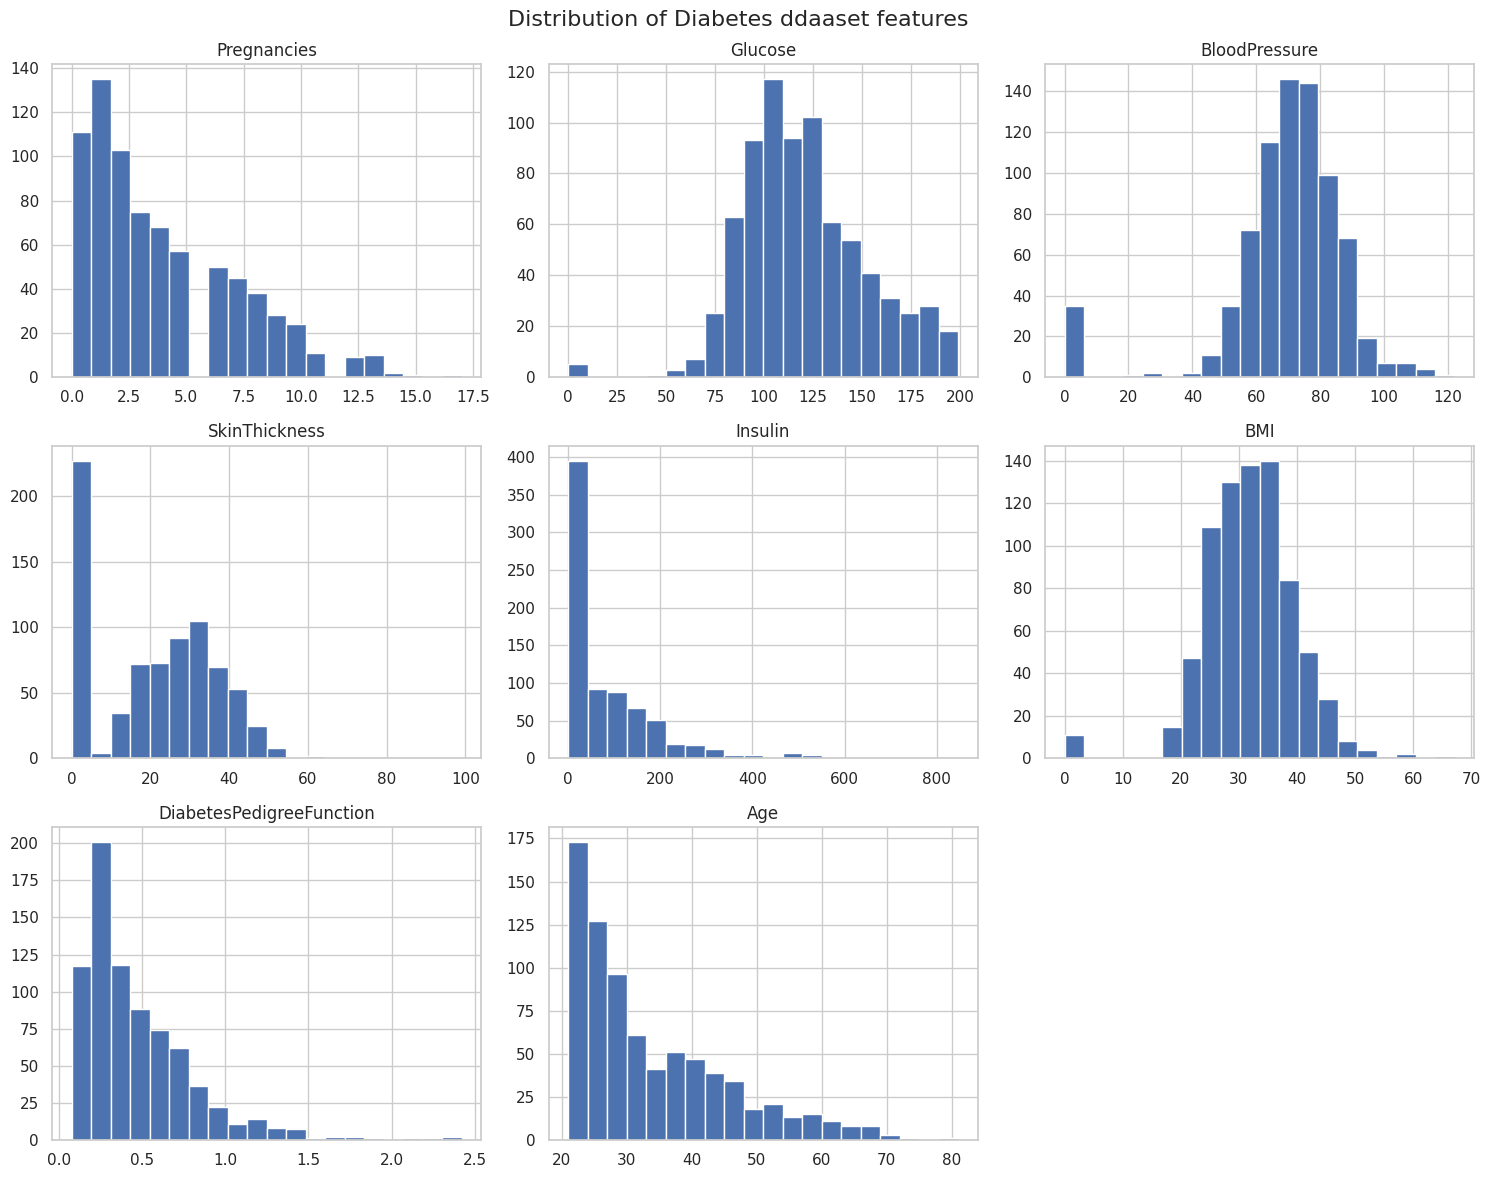

In [ ]:
features = df.drop(columns ="Outcome").columns
df[features].hist(figsize=(15,12),bins=20)
plt.suptitle("Distribution of Diabetes ddaaset features ",fontsize=16)
plt.tight_layout()
plt.show()

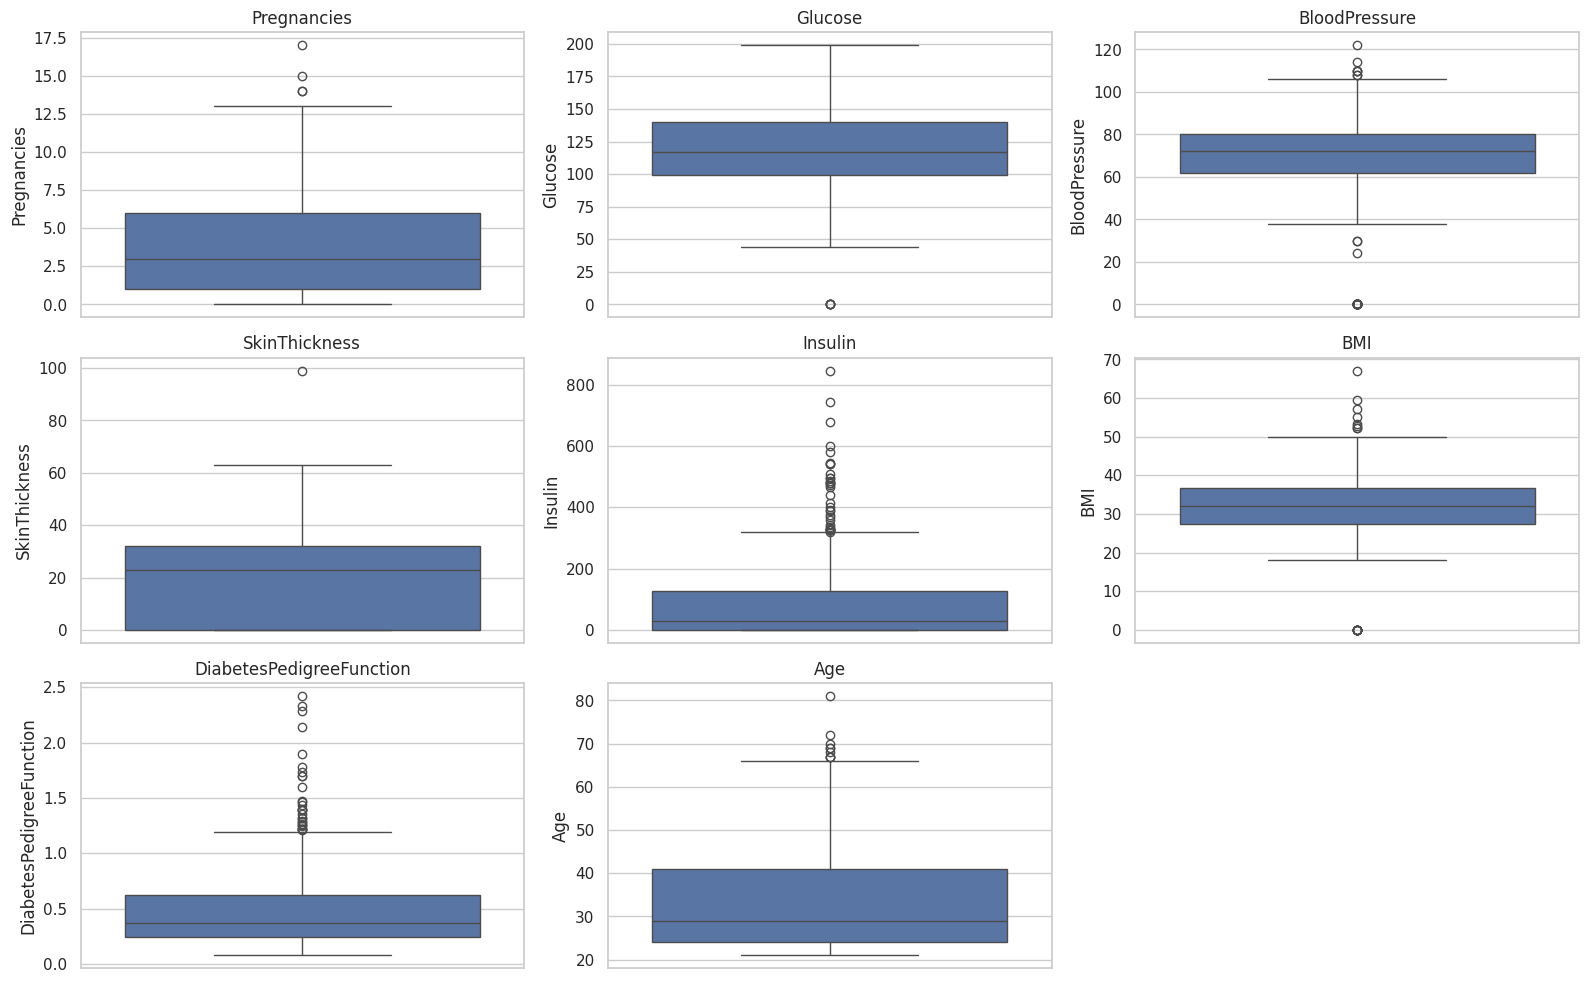

In [ ]:
plt.figure(figsize=(16,10))
for i, col in enumerate(features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
zero_columns = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = (df[zero_columns] ==  0).sum()
print("zero values:")
print(zero_counts)

zero values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


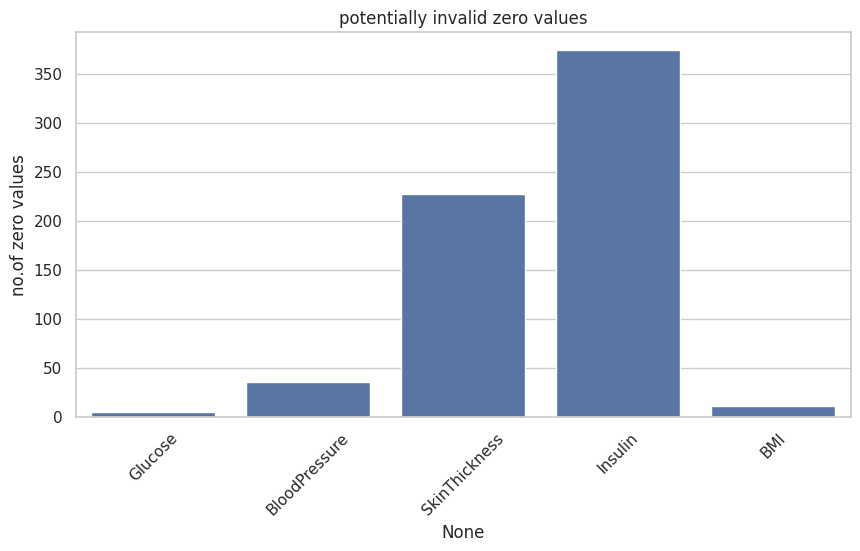

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(x=zero_counts.index,y=zero_counts.values)
plt.xticks(rotation=45)
plt.ylabel("no.of zero values")
plt.title("potentially invalid zero values")
plt.show()

In [ ]:
df_clean=df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)
print("missing values after replacing invalid zeros")
print(df_clean.isnull().sum())

missing values after replacing invalid zeros
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


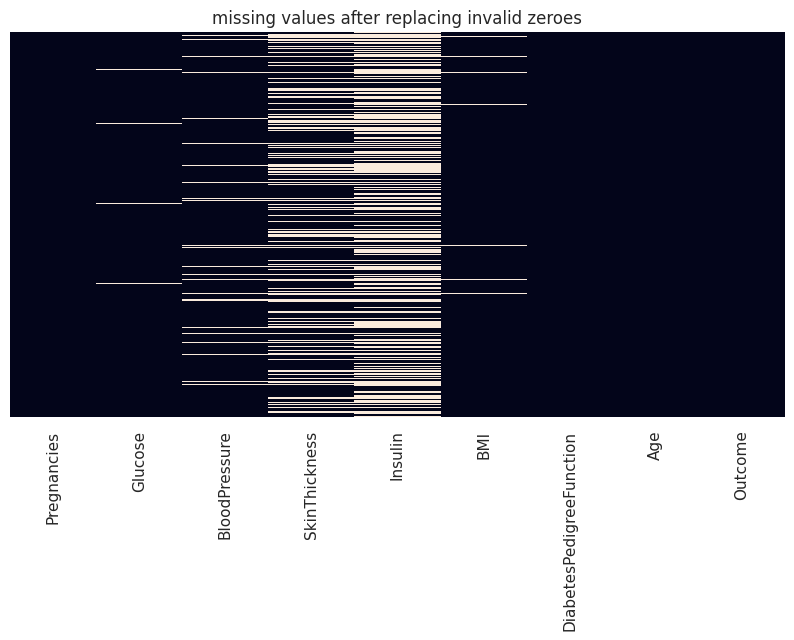

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df_clean.isnull(),cbar=False,yticklabels=False)
plt.title("missing values after replacing invalid zeroes")
plt.show()

In [ ]:
for col in zero_columns:
  df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("missing values after median imputation")
print(df_clean.isnull().sum())

missing values after median imputation
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### Multivarient Analysis

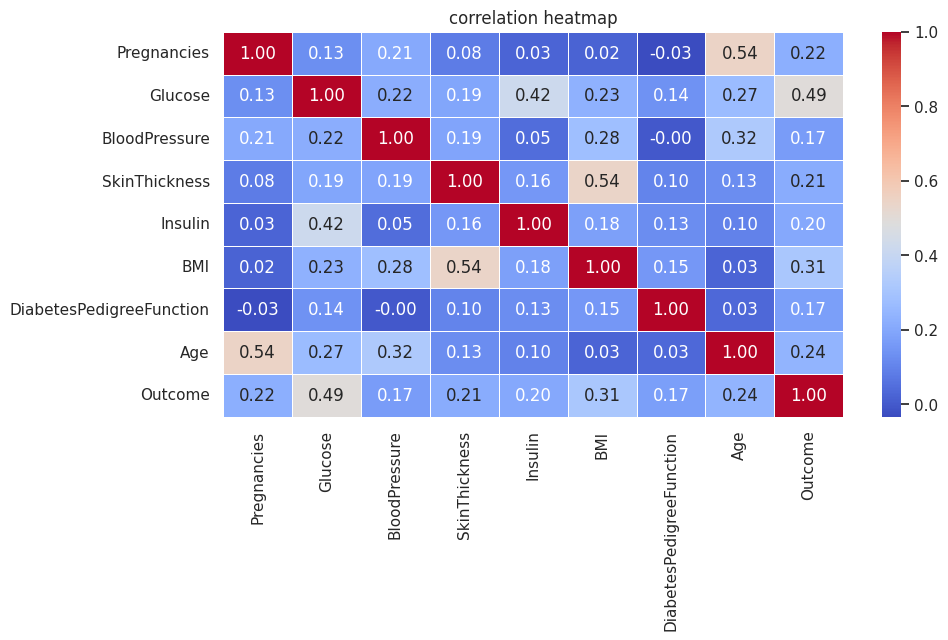

In [ ]:
plt.figure(figsize=(10,5))
correlation = df_clean.corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("correlation heatmap")
plt.show()

In [ ]:
target_corr = (df_clean.corr()["Outcome"].drop("Outcome").sort_values())
print(target_corr)

BloodPressure               0.165723
DiabetesPedigreeFunction    0.173844
Insulin                     0.203790
SkinThickness               0.214873
Pregnancies                 0.221898
Age                         0.238356
BMI                         0.312038
Glucose                     0.492782
Name: Outcome, dtype: float64


In [ ]:
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

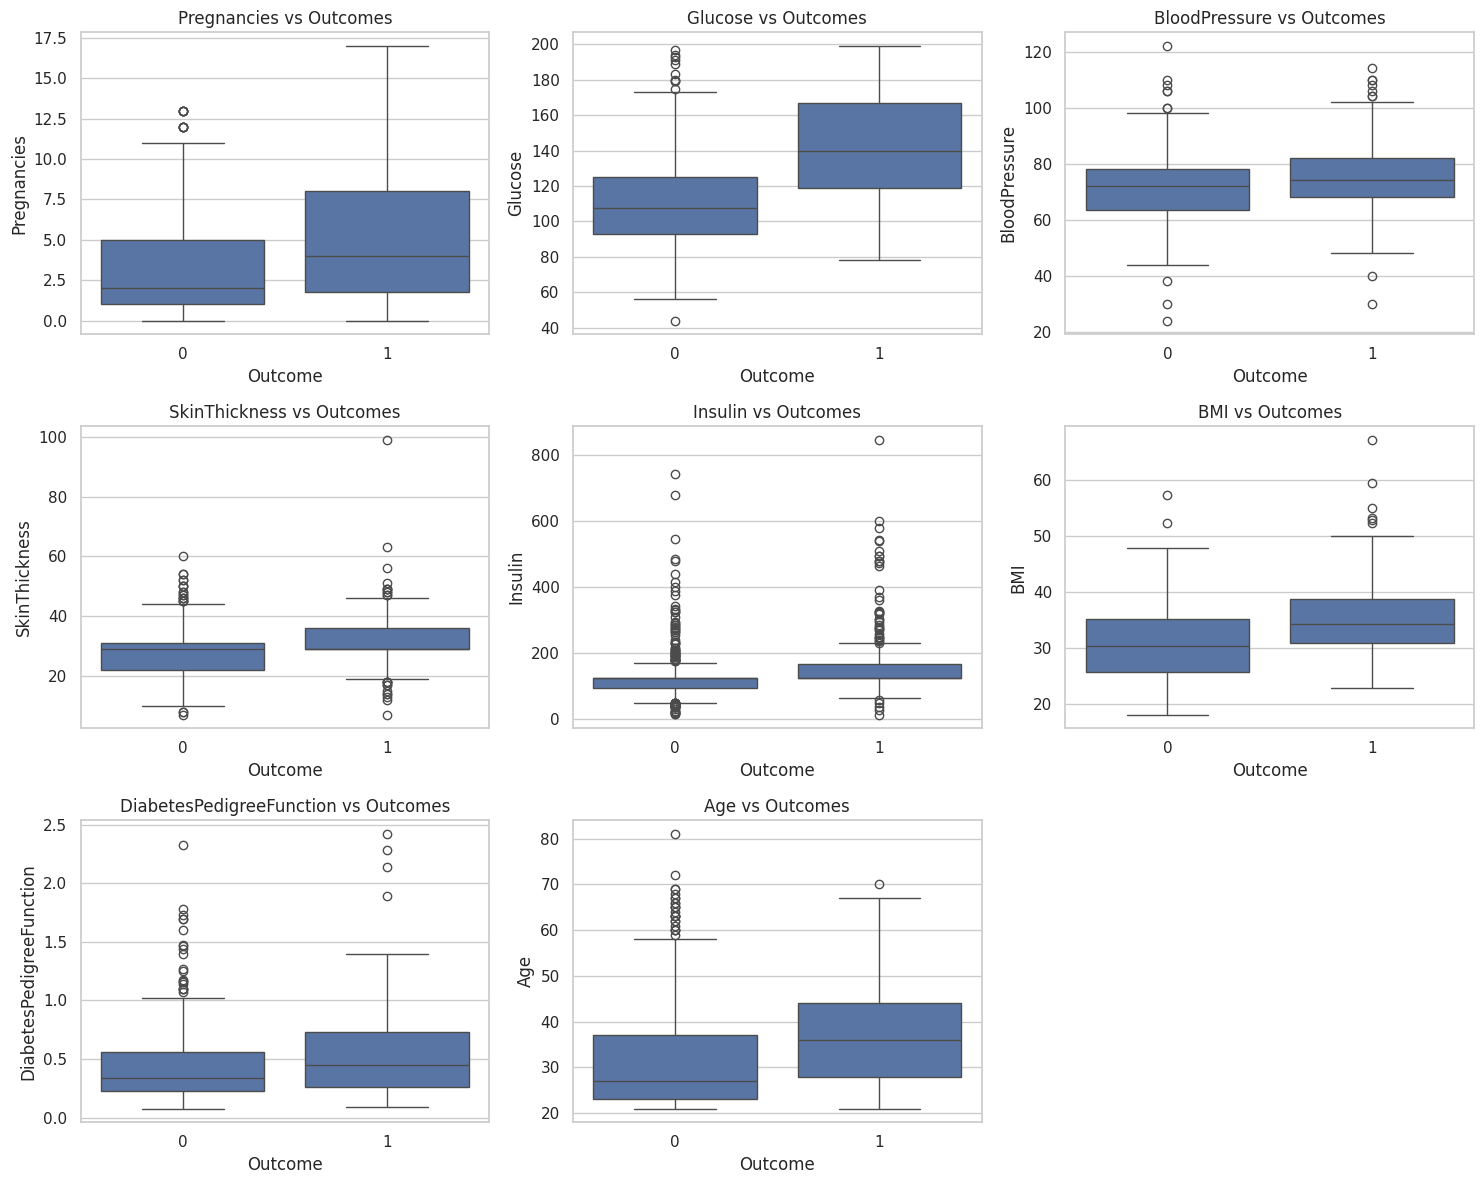

In [ ]:
plt.figure(figsize=(15,12))
for i,col in enumerate(features,1):
  plt.subplot(3,3,i)
  sns.boxplot(y=col,x="Outcome",data=df_clean)
  plt.title(f"{col} vs Outcomes")
plt.tight_layout()
plt.show()

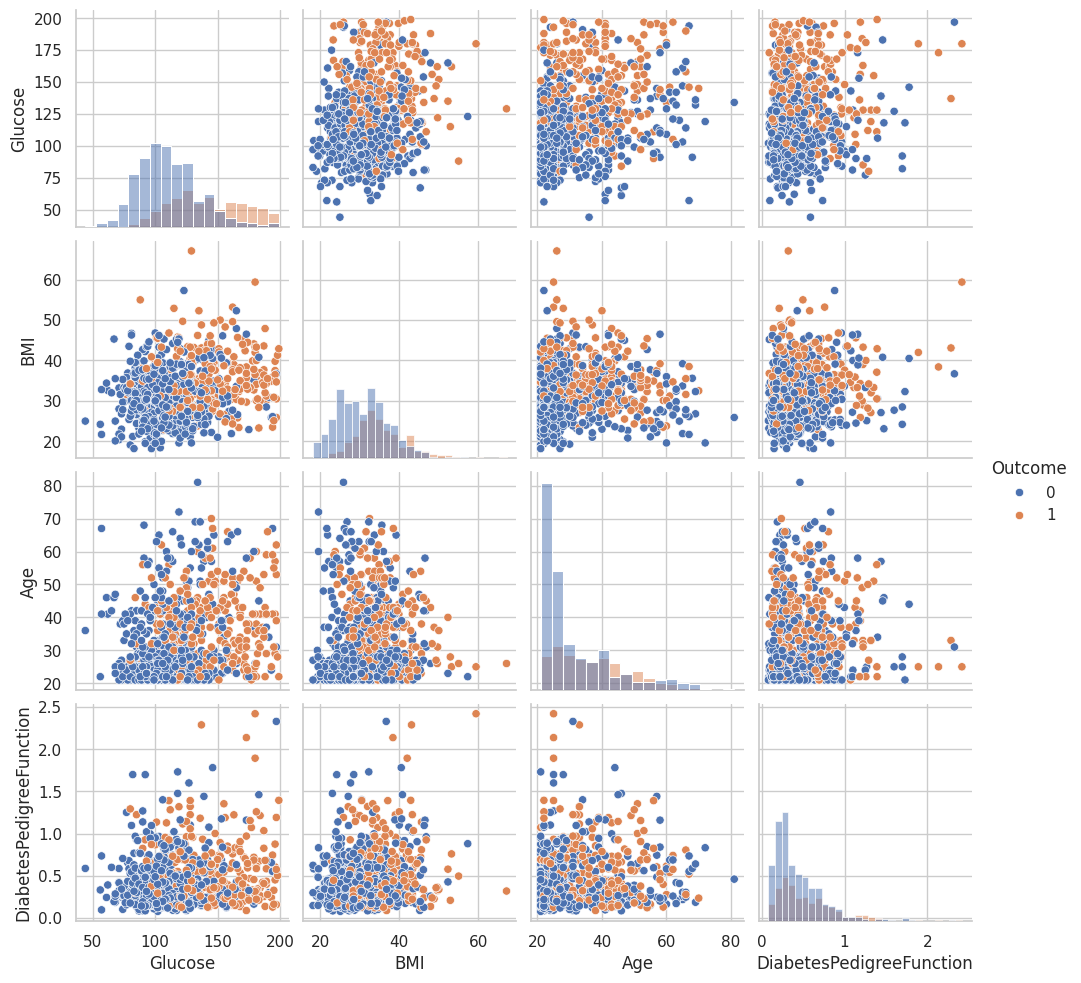

In [ ]:
selected_features = ["Glucose","BMI","Age","DiabetesPedigreeFunction","Outcome"]
sns.pairplot(df_clean[selected_features],hue="Outcome",diag_kind ="hist")
plt.show()

### Model Training

In [ ]:
X = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (768, 8)
y shape: (768,)


In [ ]:
X_train , X_test ,y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify =y)
print("X_train shape:",X_train.shape[0])
print("X_test shape:",X_test.shape[0])

X_train shape: 614
X_test shape: 154


In [ ]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_train)

array([[-0.85135507, -1.05642747, -0.82674004, ..., -0.76947697,
         0.31079384, -0.79216928],
       [ 0.35657564,  0.14439907,  0.47777235, ..., -0.41749769,
        -0.11643851,  0.56103382],
       [-0.5493724 , -0.55608308, -1.15286813, ...,  0.3597899 ,
        -0.76486207, -0.70759409],
       ...,
       [-0.85135507, -0.82293342, -0.17448384, ...,  0.82909561,
        -0.78607218, -0.28471812],
       [ 1.86648903, -0.35594533, -0.17448384, ..., -0.72547956,
        -1.01938346,  0.56103382],
       [ 0.05459296,  0.74481233, -1.15286813, ..., -0.43216349,
        -0.57700104,  0.30730824]])

In [ ]:
scaler.transform(X_test)

array([[ 0.96054099,  1.24515673, -0.66367599, ..., -0.74014536,
        -0.55579092,  0.56103382],
       [ 1.86648903, -1.79026591,  2.76066903, ...,  0.44778472,
        -0.58306107,  1.15306018],
       [-0.5493724 ,  0.01097389,  0.3147083 , ...,  0.50644793,
         0.01688223, -0.6230189 ],
       ...,
       [-0.5493724 , -1.32327781, -1.64206028, ..., -0.57882152,
         3.70138246, -0.70759409],
       [ 0.05459296,  2.07906404,  0.47777235, ...,  0.66777177,
        -0.64669142, -0.20014293],
       [-0.85135507, -1.69019703,  0.47777235, ...,  0.11047124,
        -0.16794879, -1.04589487]])

In [ ]:
comparison = pd.DataFrame({
    "Original mean":X_train.mean(),
    "Original std":X_train.std(),
    "Scaled mean":X_train_scaled.mean(),
    "Scaled std":X_train_scaled.std()
})
display(comparison)

,Original mean,Original std,Scaled mean,Scaled std
Pregnancies,3.819218,3.314148,-1.566789e-16,1.0
Glucose,121.671010,30.003794,-1.566789e-16,1.0
BloodPressure,72.140065,12.275119,-1.566789e-16,1.0
SkinThickness,29.042345,8.891855,-1.566789e-16,1.0
Insulin,137.705212,78.764767,-1.566789e-16,1.0
BMI,32.446743,6.824142,-1.566789e-16,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.566789e-16,1.0
Age,33.366450,11.833438,-1.566789e-16,1.0


### KNN

In [ ]:
K = 5
knn_classifier = KNeighborsClassifier(n_neighbors=K)
knn_classifier.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:

y_pred = knn_classifier.predict(X_test_scaled)
print("Prediction")
print(y_pred[:20])

Prediction
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [ ]:
y_prob=knn_classifier.predict_proba(X_test_scaled)[:,1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.7532467532467533


In [ ]:
precision = precision_score(y_test, y_pred)
print("Precision:",precision)
recall = recall_score(y_test, y_pred)
print("Recall:",recall)
f1 = f1_score(y_test, y_pred)
print("F1 score:",f1)


Precision: 0.66
Recall: 0.6111111111111112
F1 score: 0.6346153846153846


In [ ]:
print(classification_report(y_test, y_pred, target_names = ["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[83 17]
 [21 33]]


In [ ]:
k_values=range(1,31)
train_accuracy=[]
test_accuracy=[]
for k in k_values:
  model=KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_scaled,y_train)
  train_accuracy.append(model.score(X_train_scaled,y_train))
  test_accuracy.append(model.score(X_test_scaled,y_test))

Text(0.5, 1.0, 'Knn accuracy vs k')

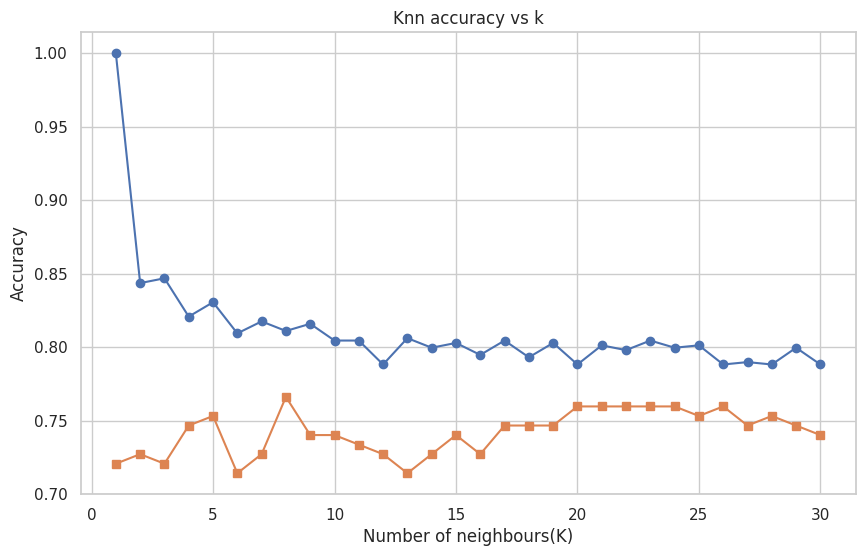

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,marker="o",label="Traiing Accuracy")
plt.plot(k_values,test_accuracy,marker="s",label="Testing Accuracy")
plt.xlabel("Number of neighbours(K)")
plt.ylabel("Accuracy")
plt.title("Knn accuracy vs k")

In [ ]:
best_k_accuracy=k_values[np.argmax(test_accuracy)]
best_accuracy=max(test_accuracy)
print("Best k value:",best_k_accuracy)
print("Best accuracy:",best_accuracy)

Best k value: 8
Best accuracy: 0.7662337662337663


In [ ]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_scores=[]
for k in range(1,31):
   model=KNeighborsClassifier(n_neighbors=k)
   scores=cross_val_score(model,X_train_scaled,y_train,cv=cv,scoring="accuracy")
   cv_scores.append(scores.mean())

In [ ]:
best_k_cv=np.argmax(cv_scores)+1
best_accuracy_cv=max(cv_scores)
print("Best k value:",best_k_cv)
print("Best accuracy:",best_accuracy_cv)


Best k value: 13
Best accuracy: 0.7703718512594963


In [ ]:
param_grid = {
    "n_neighbors": list(range(3, 31, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]
}

In [ ]:
grid_search=GridSearchCV(estimator=KNeighborsClassifier(),param_grid=param_grid,cv=5,scoring="accuracy",n_jobs=-1)
grid_search.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan', 'minkowski'],
                         'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23,
                                         25, 27, 29],
                         'p': [1, 2], 'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [ ]:
print("Best Paramter:")
print(grid_search.best_params_)

Best Paramter:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}
